In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
from scipy import stats
from matplotlib.lines import Line2D


In [2]:
#plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [3]:
domainM='GRq'; nx=ny=10
domainM='GRq'
ds_TTZ_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
    'TTZ_daymean_MARv3.14_ER5_spin2_GRq_*.nc')['TTZ'].sel(ZTQLEV=2)
ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
ds_TTZ=ds_TTZ[:,ny:-ny,nx:-nx]

In [4]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [5]:
#ds_TF=ds_SF+ds_RF

In [6]:
lonmin, lonmax = 86.4, 87.2
latmin, latmax = 27.6, 28.2

mask_khumbu = (
    (LONS >= lonmin) & (LONS <= lonmax) &
    (LATS >= latmin) & (LATS <= latmax)
)

In [7]:

def daily_lapse_rate(ds_TTZ, dsSH, mask_region):

    Z = dsSH.values[mask_region]   # elevation only once

    lapse_rates = []

    for t in ds_TTZ.time:
        T = ds_TTZ.sel(time=t).values[mask_region]

        mask = np.isfinite(T) & np.isfinite(Z)

        slope, _, _, _, _ = stats.linregress(
            Z[mask],
            T[mask]
        )

        lapse_rates.append(slope * 1000)   # °C/km

    return xr.DataArray(
        lapse_rates,
        coords=[ds_TTZ.time],
        dims=["time"],
        name="lapse_rate"
    )

In [8]:
lr_khumbu = daily_lapse_rate(ds_TTZ, dsSH, mask_khumbu)

/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/numpy/core/_methods.py:179: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


In [9]:
##GLACIOCLIM
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_meteo/'
#
##
#Pyramid
#5035 m a.s.l (off-glacier)	2019 à 2024 X
#
#Mera La ML
#5350 m a.s.l (off-glacier)	2013 à 2024 X
#Mera 5770 M5
#5770 m a.s.l (on-glacier)	2017 à 2024
#Mera Naulek MN
#5350 m a.s.l (on-glacier)	2012 à 2024 X
#Mera Summit MS
#6350 m a.s.l (on-glacier)	2013 à 2016 X


In [10]:
#West Changri Nup
#5360 m a.s.l (on-glacier)	2010 à 2012
#2012 à 2014
#2014 à 2024
#North Changri Nup
#5470 m a.s.l (on-glacier)	2014 à 2017

In [11]:
fileName='AWS_Pyramid_2019_2024.xlsx'
lat_PYG= 27.95892;lon_PYG=86.812987;elev_PYG=5035 

xl_file_PYG= pd.ExcelFile(sourceData+fileName)
dfs_PYG = {sheet_name: xl_file_PYG.parse(sheet_name) 
          for sheet_name in xl_file_PYG.sheet_names}
File_PYG=dfs_PYG['Pyramid_2019_24']
UnitVars_PYG=['(°C)','(%)','Dist sensor-surf','Dist sensor-surf','(m/s)','AWS (°)','(m/s)','(hPa)','(W/m2)',
              '(W/m2)','(W/m2)','(W/m2)','(mm)','(°C)','(%)','(m/s)', 'Geonor (°)','(m/s)','(mm)','(mm)','(mm)']
NameVars_PYG=['Time','Tair_AWS','RH_AWS','Abl_Acc','Abl_Acc','u_AWS','Direction','u_max_AWS','Patm','SWin','SWout','LWin_cor','LWout_cor','Geonor','Tair_Geonor','RH_Geonor','u_Geonor',
              'Direction','u_max_Geonor','Geonor','Geonor','Geonor']

dfile_PYG = pd.DataFrame(data=File_PYG.loc[5:])
df_PYG=pd.DataFrame(dfile_PYG.values, columns=NameVars_PYG)
#print(df_PYG.head())

time_clean = pd.to_datetime(df_PYG["Time"], errors="coerce").values
NameVar = "tair"

ds_PYG_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_PYG["Tair_AWS"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_PYG_raw = ds_PYG_tair.resample(time='1D').mean()
#ds_daily = ds_PYG_tair.resample(time='1D').max()
#ds_daily = ds_PYG_tair.resample(time='1D').min()
#ds_daily = ds_PYG_tair.resample(time='1D').sum()
tt_daily_PYG=tt_daily_PYG_raw.tair

In [12]:
#tt_daily_PYG.plot()

In [13]:
##MeraLafinal2013_24.xlsx
###
#AWS-Mera La: Since November 2013 (AWS inserted on firm rocks – off-glacier)
#Location in WGS84, Lat: 27.735°N; Long: 86.900°E; Elevation: 5352.008 m 
#or UTM Zone 45; Easting: 490137.007 m; Northing: 3067850.613 m on 22/11/2020
###

fileName='MeraLafinal2013_24.xlsx'

xl_file_MeraLa = pd.ExcelFile(sourceData+fileName)

dfs_MeraLa = {sheet_name: xl_file_MeraLa.parse(sheet_name) 
          for sheet_name in xl_file_MeraLa.sheet_names}
File_MeraLa=dfs_MeraLa['MeraLa2013_23']

NameVars_MeraLa=['Time','Tair','RH','u','Direction','SWin','SWout','LWin','LWout','Patm']
UnitVars_MeraLa=['data/hour','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraLa = pd.DataFrame(data=File_MeraLa.loc[4:])
df_MeraLa=pd.DataFrame(dfile_MeraLa.values, columns=NameVars_MeraLa)

df_MeraLa.head()
### Opening one column + converting into an array
Tair_ar=[float(i) for i in df_MeraLa.Tair.values]

NameVar="Tair"; Var_ar=Tair_ar

start, end = df_MeraLa.Time.values[0], df_MeraLa.Time.values[-1]
time = pd.date_range(start, end, freq='30min')
ds_MeraLa = xr.Dataset({NameVar: ("time",np.asarray(Var_ar)), "time": time})

tt_daily_ML = ds_MeraLa.Tair.resample(time='D').mean()


In [14]:
#tt_daily_ML.plot()

In [15]:
##Mera Naulek
def NewTime(df,NameVar, Var_ar, freq):
    start = df.Time.values[0]
    time = pd.date_range(start=start, periods=len(Var_ar), freq=freq)
    ds = xr.DataArray(Var_ar, dims='time', coords={'time': time}, name=NameVar)
    return ds

fileName='Naulekfinal2012_24.xlsx'

xl_file_MeraNaulek = pd.ExcelFile(sourceData+fileName)

dfs_MeraNaulek = {sheet_name: xl_file_MeraNaulek.parse(sheet_name) 
          for sheet_name in xl_file_MeraNaulek.sheet_names}

File_MeraNaulek=dfs_MeraNaulek['Naulekfinal2012_24']

NameVars_MeraNaulek=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','Abl/acc dist sensor surf','tilt metter XAXIS','tilt meter YAXIX']
UnitVars_MeraNaulek=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','m','degrees','degrees']


##Define new DataFrame and changing name of columns
dfile_MeraNaulek = pd.DataFrame(data=File_MeraNaulek.loc[4:])
df_MeraNaulek=pd.DataFrame(dfile_MeraNaulek.values, columns=NameVars_MeraNaulek)
### Opening one column + converting into an array
Tairlow_ar=[float(i) for i in df_MeraNaulek.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar=[float(i) for i in df_MeraNaulek.Tairhigh.values] 
    
ds_Tlow_MeraNaulek=NewTime(df_MeraNaulek,'Tairlow',Tairlow_ar,'30min')
ds_Thigh_MeraNaulek=NewTime(df_MeraNaulek,'Tairhigh',Tairhigh_ar,'30min')
tlow_daily_mean_MeraNaulek  = ds_Tlow_MeraNaulek.resample(time='D').mean()
thigh_daily_mean_MeraNaulek  = ds_Thigh_MeraNaulek.resample(time='D').mean()



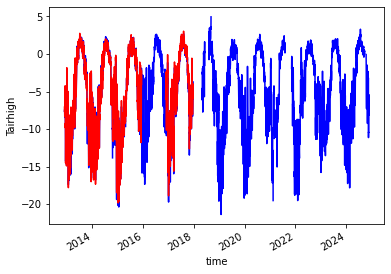

In [16]:
tlow_daily_mean_MeraNaulek.plot(color='blue')
thigh_daily_mean_MeraNaulek.plot(color='red')

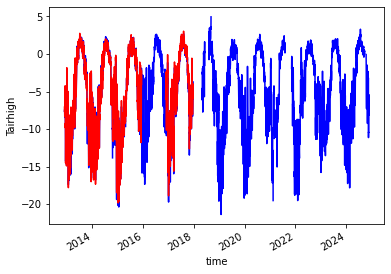

In [17]:
tlow_aligned, thigh_aligned = xr.align(
    tlow_daily_mean_MeraNaulek,
    thigh_daily_mean_MeraNaulek,
    join="inner"
)
tlow_aligned.plot(color='blue')
thigh_aligned.plot(color='red')

In [18]:
tmean = (tlow_aligned + thigh_aligned) / 2
#tmean.plot()

In [19]:
tt_daily_MN=tmean
tmean.time[-1]

<xarray.DataArray 'time' ()>
array('2024-11-26T00:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2024-11-26

In [20]:
## Mera Summit

fileName='MeraSummit_2013-16.xlsx'

xl_file_MeraSummit = pd.ExcelFile(sourceData+fileName)

df_MeraSummit= {sheet_name: xl_file_MeraSummit.parse(sheet_name)     
       for sheet_name in xl_file_MeraSummit.sheet_names}
Data_MeraSummit=df_MeraSummit['MeraSummit2013_16']                  
NameVars_MeraSummit=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','T1snow','T2snow','T3snow','T4snow','T5snow','T6snow','Abl/acc dist sensor surf','Quality number SR50','Patm']
UnitVars_MeraSummit=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','C','C','C','C','C','C','m','','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraSummit= pd.DataFrame(data=Data_MeraSummit.loc[4:]) 
df_MeraSummit=pd.DataFrame(dfile_MeraSummit.values, columns=NameVars_MeraSummit) 

### Opening one column + converting into an array
Tairlow_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairhigh.values] 


ds_Tlow_MeraSummit = NewTime(df_MeraSummit,'Tairlow', Tairlow_ar_MeraSummit, '30min')
ds_Thigh_MeraSummit = NewTime(df_MeraSummit,'Tairhigh', Tairhigh_ar_MeraSummit, '30min')
ds_Tmean_MeraSummit = (ds_Tlow_MeraSummit + ds_Thigh_MeraSummit) / 2
ds_Tmean_MeraSummit.name = 'Tairmean'  # optional, rename variable

tlow_daily_mean_MeraSummit  = ds_Tlow_MeraSummit.resample(time='D').mean()
thigh_daily_mean_MeraSummit  = ds_Thigh_MeraSummit.resample(time='D').mean()
tmean_daily_mean_MeraSummit  = ds_Tmean_MeraSummit.resample(time='D').mean()

tt_daily_MS=tmean_daily_mean_MeraSummit

In [21]:
fileName='Changri5360final2014_24.xlsx'

xl_file_CHA3= pd.ExcelFile(sourceData+fileName)
dfs_CHA3 = {sheet_name: xl_file_CHA3.parse(sheet_name) 
          for sheet_name in xl_file_CHA3.sheet_names}

File_CHA3=dfs_CHA3['Changri_5360_2014_23']

NameVars_CHA3 = ["Date","SWin","SWout","LWin","LWout","Tair","RH","Height/surf","u high","Direction",
                    "Flux -21cm","T1 -1cm","T2 -16cm","T3 -21cm","u low","Direction"]

dfile_CHA3= pd.DataFrame(data=File_CHA3.loc[12:])
df_CHA3=pd.DataFrame(dfile_CHA3.values, columns=NameVars_CHA3)
print(df_CHA3.head())
time_clean = pd.to_datetime(df_CHA3["Date"], errors="coerce").values
NameVar = "Tair"

ds_CHA3_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_CHA3["Tair"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_CHA3_raw = ds_CHA3_tair.resample(time='1D').mean()
tt_daily_CHA3=tt_daily_CHA3_raw.Tair

                 Date    SWin   SWout    LWin   LWout    Tair      RH  \
0 2014-11-30 13:00:00  805.12   156.7  29.026  215.88  3.2685  7.4238   
1 2014-11-30 13:30:00   759.9  147.56  195.46  379.23   3.251  7.1217   
2 2014-11-30 14:00:00   692.5  133.82  194.69  376.27  3.2897  7.5707   
3 2014-11-30 14:30:00  607.17  117.99  194.24  375.13  3.3542  7.3504   
4 2014-11-30 15:00:00  507.74  98.694  192.92  367.47  2.9335  7.2352   

  Height/surf u high Direction Flux -21cm T1 -1cm T2 -16cm T3 -21cm  u low  \
0       0.884  4.541     174.5     16.179  7.5551      NaN      NaN  4.022   
1        0.88  5.179     263.3     17.151  12.908  -3.1084  -4.2914  4.604   
2       0.875  4.239     191.5     17.638   10.97  -2.6814  -3.9885  3.804   
3       0.881   3.26     210.9     17.519  10.885  -2.3063  -3.7073  3.002   
4       0.878  3.778     175.8     16.894   9.797  -2.0093  -3.4627  3.478   

  Direction  
0     195.2  
1     293.5  
2     192.2  
3       263  
4     215.8  


In [22]:
#Mera5770 2017-2024
#	Easting (m)	Northing (m)	Elevation (m)
#	488409,424	3066148,049	5769,233

In [23]:
fileName='Mera5770final2017_24.xlsx'
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_meteo/'
xl_file_M57= pd.ExcelFile(sourceData+fileName)
dfs_M57 = {sheet_name: xl_file_M57.parse(sheet_name) 
          for sheet_name in xl_file_M57.sheet_names}

File_M57=dfs_M57['Mera_5770_2017_24']

NameVars_M57 = ["Date","Tair","RH","u","Direction","SWin","SWout","LWin_cor",
                 "LWout_cor","Abl_Acc","Patm"]
File_M57

,"AWS Mera Glacier, uncovered part",Unnamed: 1,Easting (m),Northing (m),Elevation (m),on 10 nov. 2017,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,Years 2017-22,NaN,488409.424,3066148.049,5769.233,UTM North Zone 45. WGS84,NaN,NaN,NaN,NaN,NaN
1,Date / Hour,Tair,RH,u,Direction,SWin,SWout,LWin cor,LWout cor,Abl/Acc,Patm
2,NaN,(°C),(%),(m/s),(°),(W/m2),(W/m2),(W/m2),(W/m2),Dist sensor-surf,(hPa)
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(m),NaN
4,2017-11-10 12:00:00,-9.49,20.16,NaN,NaN,820.9,546.48,143.74,316.3,NaN,527.1
...,...,...,...,...,...,...,...,...,...,...,...
113819,2024-05-08 15:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113820,2024-05-08 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113821,2024-05-08 16:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113822,2024-05-08 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
dfile_M57= pd.DataFrame(data=File_M57.loc[4:])
#print(dfile_M57.head())

In [25]:
df_M57=pd.DataFrame(dfile_M57.values, columns=NameVars_M57)
#print(df_M57.head())
time_clean = pd.to_datetime(df_M57["Date"], errors="coerce").values
NameVar = "Tair"

ds_M57_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_M57["Tair"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_M57_raw = ds_M57_tair.resample(time='1D').mean()
tt_daily_M57=tt_daily_M57_raw.Tair

In [26]:
idatePYG = str(tt_daily_PYG.time[0].values)[:10]
fdatePYG = str(tt_daily_PYG.time[-1].values)[:10]
              
idateML = str(tt_daily_ML.time[0].values)[:10]
fdateML = str(tt_daily_ML.time[-1].values)[:10]

idateMS = str(tt_daily_MS.time[0].values)[:10]
fdateMS = str(tt_daily_MS.time[-1].values)[:10]

idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]
fdateMN = str(tlow_daily_mean_MeraNaulek.time[-1].values)[:10]

#idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]

idateCHA3=str(tt_daily_CHA3.time[0].values)[:10]
fdateCHA3=str(tt_daily_CHA3.time[-1].values)[:10]

idateM57=str(tt_daily_M57.time[0].values)[:10]
fdateM57=str(tt_daily_M57.time[-1].values)[:10]


In [27]:
###
## PYRAMID Salerno
### 

In [28]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

#

                       AT   RR     AP    RH    WS  WD
TIMESTAMP                                            
1994-01-01 02:00:00 -11.9  0.0  551.4  25.0  0.00 NaN
1994-01-01 04:00:00 -13.2  0.0  551.0  23.0  0.00 NaN
1994-01-01 06:00:00 -10.5  0.0  551.1  10.0  0.26 NaN
1994-01-01 08:00:00 -10.9  0.0  551.9  17.0  0.00 NaN
1994-01-01 10:00:00  -7.1  0.0  553.1  17.0  5.58 NaN


In [29]:
print(df_AWSSC.head())

                     AT  AP  RH  WS  WD
TIMESTAMP                              
2008-05-01 00:00:00 NaN NaN NaN NaN NaN
2008-05-01 01:00:00 NaN NaN NaN NaN NaN
2008-05-01 02:00:00 NaN NaN NaN NaN NaN
2008-05-01 03:00:00 NaN NaN NaN NaN NaN
2008-05-01 04:00:00 NaN NaN NaN NaN NaN


In [30]:
 #Daily total precipitation (sum of hourly rates)
tt_AWS0_daily = df_AWS0['AT'].resample('D').mean()
tt_AWS1_daily = df_AWS1['AT'].resample('D').mean()
tt_AWS2_daily = df_AWS2['AT'].resample('D').mean()
tt_AWS3_daily = df_AWS3['AT'].resample('D').mean()
tt_AWS4_daily = df_AWS4['AT'].resample('D').mean()
tt_AWS5_daily = df_AWS5['AT'].resample('D').mean()
tt_AWSSC_daily = df_AWSSC['AT'].resample('D').mean()
tt_CNG_daily = df_CNG['AT'].resample('D').mean()


In [31]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    #print(df.head())
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df[df < -100] = np.nan
    
tt_bc_daily = df_bc['T_HMP'].resample('D').mean()
tt_c2_daily = df_c2['T_HMP'].resample('D').mean()
tt_phort_daily = df_phort['T_HMP'].resample('D').mean()
tt_bish_daily = df_bish['T_HMP'].resample('D').mean()
tt_sc_daily = df_sc['T_HMP'].resample('D').mean()


                     T_HMP      RH   PRESS  PRECIP
TIMESTAMP                                         
2019-10-17 13:00:00 -4.078  99.578  536.71     0.0
2019-10-17 14:00:00 -4.282  92.273  537.15     0.0
2019-10-17 15:00:00 -3.584  86.358  537.28     0.0
2019-10-17 16:00:00 -3.458  88.629  537.25     0.0
2019-10-17 17:00:00 -3.966  74.045  537.22     0.0


In [32]:
###Coordinates

In [33]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CHA3, lat_CHA3, elev_CHA3 = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 6351  # estimated same as MN, if not otherwise specified

# MC (Mera Central; high camp 5770)
eastingM57, northingM57 = 488409.424, 3066148.049
lon_M57, lat_M57 = transformer.transform(eastingM57, northingM57)
elev_M57 = 5769.233

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MK", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    #{"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PHE", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summit", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "M57", "Name": "Mera Camp 5770", "Lat": lat_M57, "Lon": lon_M57, "Elev_m": elev_M57, "Timestep": "1h"},
    {"ID": "PYG", "Name": "Pyramid-AWS", "Lat": lat_PYG, "Lon": lon_PYG, "Elev_m": elev_PYG, "Timestep": "1h"},
    {"ID": "CHA", "Name": "CHA3", "Lat": lat_CHA3, "Lon": lon_CHA3, "Elev_m": elev_CHA3, "Timestep": "1h"},
]


# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
     MK         Mera Naulek  27.717723    86.897390     5360.000        1h     
     ML             Mera La  27.735000    86.900000     5352.008        1h     
     KH               Khare  27.744247    86.877614     4888.000        1h     
    PHE            Pheriche  27.895049    86.819729     4260.000        1h     
     PY             Pyramid  27.957822    86.812969     5035.000        1h     
     MS         Mera Summit  27.706566    86.873753     6351.000        1h     
    M57      Mera Camp 5770  27.719608    86.882420     5769.233        1h     
    PYG         Pyramid-AWS  27.958920    86.812987     5035.000        1h     
    CHA                CHA3  27.983363    86.779484     5360.000        1h     


In [34]:
# Station coordinates and elevations
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Metadata list using the variable names
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": lat_AWSSC, "Lon": lon_AWSSC, "Elev_m": elev_AWSSC, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": lat_CNG, "Lon": lon_CNG, "Elev_m": elev_CNG, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": lat_AWS0, "Lon": lon_AWS0, "Elev_m": elev_AWS0, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": lat_AWS1, "Lon": lon_AWS1, "Elev_m": elev_AWS1, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": lat_AWS2, "Lon": lon_AWS2, "Elev_m": elev_AWS2, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": lat_AWS3, "Lon": lon_AWS3, "Elev_m": elev_AWS3, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": lat_AWS4, "Lon": lon_AWS4, "Elev_m": elev_AWS4, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": lat_AWS5, "Lon": lon_AWS5, "Elev_m": elev_AWS5, "Timestep": "1h"},
    #{"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": lat_Pyr, "Lon": lon_Pyr, "Elev_m": elev_Pyr, "Timestep": "1month"},
]
# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID          Name    Lat    Lon  Elev_m Timestep
0    AWSSC     South Col  27.98  86.76    7986       1h
1  CNG_SNP   Changri Nup  27.96  86.93    5700       1h
2     AWS0       Pyramid  27.96  86.81    5035       1h
3     AWS1       Pyramid  27.96  86.81    5035       1h
4     AWS2      Pheriche  27.90  86.82    4260       1h
5     AWS3         Lukla  27.70  86.72    2660       1h
6     AWS4  Kala Patthar  27.99  86.83    5600       1h
7     AWS5        Namche  27.80  86.71    3570       1h


In [35]:
# NatGeo Everest AWS coordinates
#Phortse Base Camp Camp II South Col Balcony  Table1 Matthews
#Latitude (°N) 27.8456 27.9952 27.9810 27.9719 27.9826
#lat_phort,lat_bc,lat_c2,lat_sc,lat_bish=27.8456, 27.9952, 27.9810, 27.9719, 27.9826
#Longitude (°E) 86.7472 86.8406 86.9023 86.9295 86.9292
#lon_phort,lon_bc,lon_c2,lon_sc,lon_bish=86.7472, 86.8406, 86.9023 ,86.9295 ,86.9292
#Elevation (m MSL) 3,810 5,315 6,464 7,945 8,430
#elev_phort,elev_bc,elev_c2,elev_sc,elev_bish=3810, 5315 ,6464 ,7945, 8430
# BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc, lon_bc, elev_bc = 27.9952, 86.8406, 5315

# CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2, lon_c2, elev_c2 = 27.9810, 86.9023, 6464 

# PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort, lon_phort, elev_phort = 27.8456, 86.7472, 3810 

# BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish, lon_bish, elev_bish = 27.9735, 86.9308, 8810 

# MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc, lon_sc, elev_sc = 27.9719, 86.9295, 7945


# Define metadata for Everest AWS network using variables
stations_info_everest = [
    {"ID": "BC", "Name": "Base Camp AWS", "Lat": lat_bc, "Lon": lon_bc, "Elev_m": elev_bc},
    {"ID": "C2", "Name": "Camp II AWS", "Lat": lat_c2, "Lon": lon_c2, "Elev_m": elev_c2},
    {"ID": "PHO", "Name": "Phortse AWS", "Lat": lat_phort, "Lon": lon_phort, "Elev_m": elev_phort},
    {"ID": "BIS", "Name": "Bishop Rock AWS", "Lat": lat_bish, "Lon": lon_bish, "Elev_m": elev_bish},
    {"ID": "SC", "Name": "Mt. Everest South Col AWS", "Lat": lat_sc, "Lon": lon_sc, "Elev_m": elev_sc},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
#print(df_everest_stations)


In [36]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Ev-K2-CNR")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "GLACIOCLIM")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
#print(f"Total stations merged: {len(stations_all)}")
#print(stations_all.keys())

In [37]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

#print(df_station_to_grid.to_string(index=False))


In [38]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
#jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MK"]
#jCH, iCH = nearest_indices["CH"]
jCHA3, iCHA3 = nearest_indices["CHA"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PHE"]
jPY, iPY = nearest_indices["PY"]
jPYG, iPYG = nearest_indices["PYG"]
jMS, iMS = nearest_indices["MS"]
jM57, iM57 = nearest_indices["M57"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["BC"]
jc2, ic2     = nearest_indices["C2"]
jphort, iphort = nearest_indices["PHO"]
jbish, ibish   = nearest_indices["BIS"]
jsc, isc       = nearest_indices["SC"]

# Optional: save lookup table
df_station_to_grid.to_csv("/bettik/PROJECTS/pr-regional-climate/santolam/station_grid_lookup_MARnxny10.csv", index=False)


In [39]:
"""

lonmin, lonmax = 86.65, 87.#86.4, 87.2
latmin, latmax = 27.7, 28.1

mask_domain = (
    (LONS >= lonmin) & (LONS <= lonmax) &
    (LATS >= latmin) & (LATS <= latmax)
)

"""

'\n\nlonmin, lonmax = 86.65, 87.#86.4, 87.2\nlatmin, latmax = 27.7, 28.1\n\nmask_domain = (\n    (LONS >= lonmin) & (LONS <= lonmax) &\n    (LATS >= latmin) & (LATS <= latmax)\n)\n\n'

In [40]:
##Glacio
#rr_daily_PY=RR_PY.resample(time='D').sum()
#rr_daily_PH=RR_PH.resample(time='D').sum()
#rr_daily_KH=RR_KH.resample(time='D').sum()

#idatePY = str(rr_daily_PY.time[0].values)[:10]
#fdatePY = str(rr_daily_PY.time[-1].values)[:10]
#idatePH = str(rr_daily_PH.time[0].values)[:10]
#fdatePH = str(rr_daily_PH.time[-1].values)[:10]
#idateKH = str(rr_daily_KH.time[0].values)[:10]
#fdateKH = str(rr_daily_KH.time[-1].values)[:10]


ts_TTZ_CHA3 = ds_TTZ[:, jCHA3, iCHA3].sel(time=slice(idateCHA3, fdateCHA3))

ts_TTZ_PYG = ds_TTZ[:, jPYG, iPYG].sel(time=slice(idatePYG, fdatePYG))

ts_TTZ_ML = ds_TTZ[:, jML, iML].sel(time=slice(idateML, fdateML))
ts_TTZ_MN = ds_TTZ[:, jMN, iMN].sel(time=slice(idateMN, fdateMN))


ts_TTZ_MS = ds_TTZ[:, jMS, iMS].sel(time=slice(idateMS, fdateMS))
ts_TTZ_M57 = ds_TTZ[:, jM57, iM57].sel(time=slice(idateM57, fdateM57))


In [41]:
## Salerno
# Daily total precipitation (sum of hourly rates)
#rr_AWS0_daily = df_AWS0['RR'].resample('D').sum()
#rr_AWS1_daily = df_AWS1['RR'].resample('D').sum()
#rr_AWS2_daily = df_AWS2['RR'].resample('D').sum()
#rr_AWS3_daily = df_AWS3['RR'].resample('D').sum()
#rr_AWS4_daily = df_AWS4['RR'].resample('D').sum()
#rr_AWS5_daily = df_AWS5['RR'].resample('D').sum()
#jAWS0, iAWS0 
# --- Define date ranges for each AWS based on observations ---
idate_AWS0 = str(tt_AWS0_daily.index[0].date())
fdate_AWS0 = str(tt_AWS0_daily.index[-1].date())
idate_AWS1 = str(tt_AWS1_daily.index[0].date())
fdate_AWS1 = str(tt_AWS1_daily.index[-1].date())
idate_AWS2 = str(tt_AWS2_daily.index[0].date())
fdate_AWS2 = str(tt_AWS2_daily.index[-1].date())
idate_AWS3 = str(tt_AWS3_daily.index[0].date())
fdate_AWS3 = str(tt_AWS3_daily.index[-1].date())
idate_AWS4 = str(tt_AWS4_daily.index[0].date())
fdate_AWS4 = str(tt_AWS4_daily.index[-1].date())
idate_AWS5 = str(tt_AWS5_daily.index[0].date())
fdate_AWS5 = str(tt_AWS5_daily.index[-1].date())
idate_CNG = str(tt_CNG_daily.index[0].date())
fdate_CNG = str(tt_CNG_daily.index[-1].date())


# --- Compute RF, SF, TF for each AWS station ---
ts_TTZ_AWS0 = ds_TTZ[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))

ts_TTZ_AWS1 = ds_TTZ[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))

ts_TTZ_AWS2 = ds_TTZ[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))

ts_TTZ_AWS3 = ds_TTZ[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))

ts_TTZ_AWS4 = ds_TTZ[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))

ts_TTZ_AWS5 = ds_TTZ[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))

ts_TTZ_CNG = ds_TTZ[:, jCNG, iCNG].sel(time=slice(idate_CNG, fdate_CNG))


In [42]:
##Nat geo
##
'''
tt_bc_daily = df_bc['T_HMP'].resample('D').mean()
tt_c2_daily = df_c2['T_HMP'].resample('D').mean()
tt_phort_daily = df_phort['T_HMP'].resample('D').mean()
tt_bish_daily = df_bish['T_HMP'].resample('D').mean()
tt_sc_daily = df_sc['T_HMP'].resample('D').mean()
'''

idate_bc = str(tt_bc_daily.index[0].date())
fdate_bc = str(tt_bc_daily.index[-1].date())

idate_c2 = str(tt_c2_daily.index[0].date())
fdate_c2 = str(tt_c2_daily.index[-1].date())

idate_phort = str(tt_phort_daily.index[0].date())
fdate_phort = str(tt_phort_daily.index[-1].date())

idate_bish = str(tt_bish_daily.index[0].date())
fdate_bish = str(tt_bish_daily.index[-1].date())

idate_sc = str(tt_sc_daily.index[0].date())
fdate_sc = str(tt_sc_daily.index[-1].date())

ts_TTZ_bc = ds_TTZ[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))

ts_TTZ_c2 = ds_TTZ[:, jc2, ic2].sel(time=slice(idate_c2, fdate_c2))

ts_TTZ_phort = ds_TTZ[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))

ts_TTZ_bish =ds_TTZ[:, jbish, ibish].sel(time=slice(idate_bish, fdate_bish))

ts_TTZ_sc= ds_TTZ[:, jsc, isc].sel(time=slice(idate_sc, fdate_sc))



In [43]:
#elev_M57

In [44]:
lr_daily=lr_khumbu 

In [45]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$')
##Lapse rate
elev_model_ML = float(dsSH[jML, iML])
elev_model_MS = float(dsSH[jMS, iMS])
elev_model_MN = float(dsSH[jMN, iMN])
elev_model_CHA3 = float(dsSH[jCHA3, iCHA3])
elev_model_PYG = float(dsSH[jPYG, iPYG])
elev_model_M57 = float(dsSH[jM57, iM57])

# --- Elevation differences in km ---
dz_ML = (elev_ML-elev_model_ML) / 1000
dz_MS = (elev_MS-elev_model_MS) / 1000
dz_MN = (elev_MN-elev_model_MN) / 1000
dz_PYG = (elev_PYG-elev_model_PYG) / 1000
dz_CHA3 = (elev_CHA3-elev_model_CHA3) / 1000
dz_M57 = (elev_M57-elev_model_M57) / 1000

# --- Corrected series using daily lapse rate ---
ts_TTZ_ML_lr = ts_TTZ_ML + lr_daily * dz_ML
ts_TTZ_MS_lr = ts_TTZ_MS + lr_daily * dz_MS
ts_TTZ_MN_lr = ts_TTZ_MN + lr_daily * dz_MN
ts_TTZ_PYG_lr = ts_TTZ_PYG + lr_daily * dz_PYG
ts_TTZ_CHA3_lr = ts_TTZ_CHA3 + lr_daily * dz_CHA3
ts_TTZ_M57_lr = ts_TTZ_M57 + lr_daily * dz_M57



$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$


In [46]:
import matplotlib.pyplot as plt

# --- Observed daily mean temperature series ---
stations_tt_daily_glacioclim = {
    "MeraLa": tt_daily_ML,
    "MeraSummit": tt_daily_MS,
     "MeraNaulek": tt_daily_MN,
    "Pyramid": tt_daily_PYG,
    "ChangriA3": tt_daily_CHA3,
    "Mera5770": tt_daily_M57
}

# --- Model TTZ (temperature) at corresponding locations ---
ts_TTZ_model_glacioclim = {
    "MeraLa": ts_TTZ_ML,
    "MeraSummit": ts_TTZ_MS,
     "MeraNaulek": ts_TTZ_MN,
    "Pyramid": ts_TTZ_PYG,
    "ChangriA3": ts_TTZ_CHA3,
    "Mera5770": ts_TTZ_M57
}

ts_TTZ_model_lr_glacioclim = {
    "MeraLa": ts_TTZ_ML_lr,
    "MeraSummit": ts_TTZ_MS_lr,
     "MeraNaulek": ts_TTZ_MN_lr,
    "Pyramid": ts_TTZ_PYG_lr,
    "ChangriA3": ts_TTZ_CHA3_lr,
    "Mera5770":  ts_TTZ_M57_lr

}

# --- Station elevations (from metadata or logs) ---
elev_station_glacioclim = {
    "MeraLa": elev_ML,     # m
    "MeraSummit": elev_MS, # m
    "MeraNaulek": elev_MN,
    "Pyramid": elev_PYG,
    "ChangriA3": elev_CHA3,
    "Mera5770": elev_M57

}

# --- Model elevations (from surface height field) ---
elev_model_glacioclim = {
    "MeraLa": float(dsSH[jML, iML]),
    "MeraSummit": float(dsSH[jMS, iMS]),
    "MeraNaulek":  float(dsSH[jMN,iMN]),
    "Pyramid":  float(dsSH[jPYG,iPYG]),
    "ChangriA3":  float(dsSH[jCHA3,iCHA3]),
    "Mera5770":  float(dsSH[jM57,iM57])
}



In [47]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$')
## --- Lapse-rate correction for Salerno AWS stations ---

# --- AWS0 ---
elev_model_AWS0 = float(dsSH[jAWS0, iAWS0])
dz_AWS0 = (elev_AWS0-elev_model_AWS0) / 1000
ts_TTZ_AWS0_lr = ts_TTZ_AWS0 + lr_daily * dz_AWS0

# --- AWS1 ---
elev_model_AWS1 = float(dsSH[jAWS1, iAWS1])
dz_AWS1 = (elev_AWS1-elev_model_AWS1) / 1000
ts_TTZ_AWS1_lr = ts_TTZ_AWS1 + lr_daily * dz_AWS1

# --- AWS2 ---
elev_model_AWS2 = float(dsSH[jAWS2, iAWS2])
dz_AWS2 = (elev_AWS2-elev_model_AWS2) / 1000
ts_TTZ_AWS2_lr = ts_TTZ_AWS2 + lr_daily * dz_AWS2

# --- AWS3 ---
elev_model_AWS3 = float(dsSH[jAWS3, iAWS3])
dz_AWS3 = (elev_AWS3-elev_model_AWS3 ) / 1000
ts_TTZ_AWS3_lr = ts_TTZ_AWS3 + lr_daily * dz_AWS3

# --- AWS4 ---
elev_model_AWS4 = float(dsSH[jAWS4, iAWS4])
dz_AWS4 = (elev_AWS4-elev_model_AWS4 ) / 1000
ts_TTZ_AWS4_lr = ts_TTZ_AWS4 + lr_daily * dz_AWS4

# --- AWS5 ---
elev_model_AWS5 = float(dsSH[jAWS5, iAWS5])
dz_AWS5 = (elev_AWS5-elev_model_AWS5) / 1000
ts_TTZ_AWS5_lr = ts_TTZ_AWS5 + lr_daily * dz_AWS5


$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$


In [48]:

# --- Observed daily mean temperature (°C) ---
stations_tt_daily_salerno = {
    "AWS0": tt_AWS0_daily,
    "AWS1": tt_AWS1_daily,
    "AWS2": tt_AWS2_daily,
    "AWS3": tt_AWS3_daily,
    "AWS4": tt_AWS4_daily,
    "AWS5": tt_AWS5_daily,
}

# --- Model TTZ (temperature) for each AWS station ---
ts_TTZ_model_salerno = {
    "AWS0": ts_TTZ_AWS0,
    "AWS1": ts_TTZ_AWS1,
    "AWS2": ts_TTZ_AWS2,
    "AWS3": ts_TTZ_AWS3,
    "AWS4": ts_TTZ_AWS4,
    "AWS5": ts_TTZ_AWS5,
}

ts_TTZ_model_salerno_lr = {
    "AWS0": ts_TTZ_AWS0_lr,
    "AWS1": ts_TTZ_AWS1_lr,
    "AWS2": ts_TTZ_AWS2_lr,
    "AWS3": ts_TTZ_AWS3_lr,
    "AWS4": ts_TTZ_AWS4_lr,
    "AWS5": ts_TTZ_AWS5_lr,
}

# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

# --- Model grid elevation (from surface height field) ---
elev_model_salerno = {
    "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
}




In [49]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{station}−z_{model})$$')
## --- Lapse-rate correction for Salerno AWS stations ---

# --- Base Camp ---
elev_model_bc = float(dsSH[jbc, ibc])
dz_bc = (elev_bc - elev_model_bc) / 1000
ts_TTZ_bc_lr = ts_TTZ_bc + lr_daily * dz_bc

# --- Camp 2 ---
elev_model_c2 = float(dsSH[jc2, ic2])
dz_c2 = (elev_c2 - elev_model_c2) / 1000
ts_TTZ_c2_lr = ts_TTZ_c2 + lr_daily * dz_c2

# --- Phortse ---
elev_model_phort = float(dsSH[jphort, iphort])
dz_phort = (elev_phort - elev_model_phort) / 1000
ts_TTZ_phort_lr = ts_TTZ_phort + lr_daily * dz_phort

# --- Bishop Rock ---
elev_model_bish = float(dsSH[jbish, ibish])
dz_bish = (elev_bish - elev_model_bish) / 1000
ts_TTZ_bish_lr = ts_TTZ_bish + lr_daily * dz_bish

# --- South Col ---
elev_model_sc = float(dsSH[jsc, isc])
dz_sc = (elev_sc - elev_model_sc) / 1000
ts_TTZ_sc_lr = ts_TTZ_sc + lr_daily * dz_sc


$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{station}−z_{model})$$


In [50]:
# --- Observed daily mean temperature (°C) ---
stations_tt_daily_natgeo = {
    "BaseCamp": tt_bc_daily,
    "Camp2": tt_c2_daily,
    "Phortse": tt_phort_daily,
    "BishopRock": tt_bish_daily,
    "SouthCol": tt_sc_daily,
}

# --- Model TTZ time series ---
ts_TTZ_model_natgeo = {
    "BaseCamp": ts_TTZ_bc,
    "Camp2": ts_TTZ_c2,
    "Phortse": ts_TTZ_phort,
    "BishopRock": ts_TTZ_bish,
    "SouthCol": ts_TTZ_sc,
}

ts_TTZ_model_natgeo_lr = {
    "BaseCamp": ts_TTZ_bc_lr,
    "Camp2": ts_TTZ_c2_lr,
    "Phortse": ts_TTZ_phort_lr,
    "BishopRock": ts_TTZ_bish_lr,
    "SouthCol": ts_TTZ_sc_lr,
}


# --- Station elevations (m) ---
elev_station_natgeo = {
    "BaseCamp": 5315,
    "Camp2": 6482,
    "Phortse": 3810,
    "BishopRock": 8125,
    "SouthCol": 7945,
}

# --- Model grid elevations (from dsSH) ---
elev_model_natgeo = {
    "BaseCamp": float(dsSH[jbc, ibc]),
    "Camp2": float(dsSH[jc2, ic2]),
    "Phortse": float(dsSH[jphort, iphort]),
    "BishopRock": float(dsSH[jbish, ibish]),
    "SouthCol": float(dsSH[jsc, isc]),
}



In [51]:
#rmse,bias,r
import numpy as np
from scipy.stats import pearsonr

print("=== glacioclim Stations – TTZ vs Observations ===\n")
#print(stations_tt_daily_glacioclim)
bias_list_glacioclim = []
rmse_list_glacioclim = []
corr_list_glacioclim = []
names_glacioclim= []
std_obs_list_glacioclim = []
std_mod_list_glacioclim = []
rbias_list_glacioclim=[]

bias_list_glacioclim_lr = []
rmse_list_glacioclim_lr = []
corr_list_glacioclim_lr = []
names_glacioclim_lr= []
std_mod_lr_list_glacioclim=[]
rbias_list_glacioclim_lr=[]

for name in stations_tt_daily_glacioclim.keys():
    # Observed series
    obs = stations_tt_daily_glacioclim[name]

    # Model series (original)
    mod = ts_TTZ_model_glacioclim[name].to_pandas()
    
    # Model series with lapse rate correction
    mod_lr = ts_TTZ_model_lr_glacioclim[name].to_pandas()
    
    # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mod_lr_masked = mod_lr.values[mask]
    
    ####
    mean_obs = np.mean(obs_masked) 
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    std_obs = np.std(obs_masked, ddof=1)
    std_mod = np.std(mod_masked, ddof=1)
    rbias = (bias / mean_obs) * 100.0

    # --- Lapse-rate corrected model ---
    rmse_lr = np.sqrt(np.mean((mod_lr_masked - obs_masked)**2))
    bias_lr = np.mean(mod_lr_masked - obs_masked)
    corr_lr = pearsonr(mod_lr_masked, obs_masked)[0]
    std_mod_lr = np.std(mod_lr_masked, ddof=1)
    rbias_lr = (bias_lr / mean_obs) * 100.0
    
    if np.isclose(mean_obs, 0):
        rbias = np.nan
        rbias_lr = np.nan
     
    print(
    f"{name} | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, "
    f"Rbias={rbias:.1f}%, R={corr:.2f}  | "
    f"LR-corrected: RMSE={rmse_lr:.2f}, Bias={bias_lr:.2f}, "
    f"Rbias={rbias_lr:.1f}%, R={corr_lr:.2f}")
    
  # Store in list
    bias_list_glacioclim.append(bias)
    rmse_list_glacioclim.append(rmse)
    corr_list_glacioclim.append(corr)
    std_obs_list_glacioclim.append(std_obs)
    std_mod_list_glacioclim.append(std_mod)
    names_glacioclim.append(name)
    rbias_list_glacioclim.append(rbias)
    
    bias_list_glacioclim_lr.append(bias_lr)
    rmse_list_glacioclim_lr.append(rmse_lr)
    corr_list_glacioclim_lr.append(corr_lr)
    std_mod_lr_list_glacioclim.append(std_mod_lr)
    names_glacioclim_lr.append(name)
    rbias_list_glacioclim_lr.append(rbias_lr)
 


=== glacioclim Stations – TTZ vs Observations ===

MeraLa | Original: RMSE=4.28, Bias=-3.59, Rbias=105.2%, R=0.94  | LR-corrected: RMSE=4.77, Bias=-4.13, Rbias=120.9%, R=0.94
MeraSummit | Original: RMSE=6.89, Bias=6.57, Rbias=-59.2%, R=0.96  | LR-corrected: RMSE=4.34, Bias=-3.87, Rbias=34.9%, R=0.97
MeraNaulek | Original: RMSE=2.03, Bias=1.24, Rbias=-24.0%, R=0.96  | LR-corrected: RMSE=3.07, Bias=-2.36, Rbias=45.5%, R=0.96
Pyramid | Original: RMSE=2.76, Bias=-2.17, Rbias=85.7%, R=0.96  | LR-corrected: RMSE=2.56, Bias=-1.94, Rbias=76.4%, R=0.96
ChangriA3 | Original: RMSE=3.69, Bias=-3.18, Rbias=76.9%, R=0.96  | LR-corrected: RMSE=3.61, Bias=-3.09, Rbias=74.7%, R=0.96
Mera5770 | Original: RMSE=3.48, Bias=3.20, Rbias=-43.0%, R=0.97  | LR-corrected: RMSE=3.51, Bias=-3.05, Rbias=41.0%, R=0.97


In [52]:
print("=== Salerno Stations – TTZ vs Observations ===\n")
bias_list_salerno = []
rmse_list_salerno = []
corr_list_salerno = []
std_obs_list_salerno = []
std_mod_list_salerno = []
names_salerno = []

bias_list_salerno_lr = []
rmse_list_salerno_lr = []
corr_list_salerno_lr = []
std_mod_lr_list_salerno= []
names_salerno_lr = []

rbias_list_salerno=[]
rbias_list_salerno_lr=[]

for name in stations_tt_daily_salerno.keys():
    # Observed series
    obs = stations_tt_daily_salerno[name]

    # Model series (original)
    mod = ts_TTZ_model_salerno[name].to_pandas()
    
    # Model series with lapse rate correction
    mod_lr = ts_TTZ_model_salerno_lr[name].to_pandas()
    
    # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mod_lr_masked = mod_lr.values[mask]
    
    # --- Original model ---
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    std_obs = np.std(obs_masked, ddof=1)
    std_mod = np.std(mod_masked, ddof=1)

    # --- Lapse-rate corrected model ---
    rmse_lr = np.sqrt(np.mean((mod_lr_masked - obs_masked)**2))
    bias_lr = np.mean(mod_lr_masked - obs_masked)
    corr_lr = pearsonr(mod_lr_masked, obs_masked)[0]
    std_mod_lr = np.std(mod_lr_masked, ddof=1)
    
    rbias_lr = (bias_lr / mean_obs) * 100.0
    rbias = (bias / mean_obs) * 100.0   
    if np.isclose(mean_obs, 0):
        rbias = np.nan
        rbias_lr = np.nan

    print(
    f"{name} | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, "
    f"Rbias={rbias:.1f}%, R={corr:.2f}  | "
    f"LR-corrected: RMSE={rmse_lr:.2f}, Bias={bias_lr:.2f}, "
    f"Rbias={rbias_lr:.1f}%, R={corr_lr:.2f}")
 
    # Store
    bias_list_salerno.append(bias)
    rmse_list_salerno.append(rmse)
    corr_list_salerno.append(corr)
    std_obs_list_glacioclim.append(std_obs)
    std_mod_list_glacioclim.append(std_mod)
    names_salerno.append(name)
    
    bias_list_salerno_lr.append(bias_lr)
    rmse_list_salerno_lr.append(rmse_lr)
    corr_list_salerno_lr.append(corr_lr)
    std_mod_lr_list_glacioclim.append(std_mod_lr)
    names_salerno_lr.append(name)
    rbias_list_salerno.append(rbias)
    rbias_list_salerno_lr.append(rbias_lr)

=== Salerno Stations – TTZ vs Observations ===

AWS0 | Original: RMSE=3.65, Bias=-3.06, Rbias=41.1%, R=0.95  | LR-corrected: RMSE=3.43, Bias=-2.82, Rbias=37.9%, R=0.95
AWS1 | Original: RMSE=3.31, Bias=-2.63, Rbias=35.4%, R=0.94  | LR-corrected: RMSE=3.11, Bias=-2.39, Rbias=32.2%, R=0.94
AWS2 | Original: RMSE=2.95, Bias=-2.49, Rbias=33.5%, R=0.96  | LR-corrected: RMSE=1.70, Bias=0.62, Rbias=-8.3%, R=0.96
AWS3 | Original: RMSE=2.82, Bias=-1.97, Rbias=26.6%, R=0.89  | LR-corrected: RMSE=2.86, Bias=1.91, Rbias=-25.7%, R=0.88
AWS4 | Original: RMSE=3.37, Bias=-2.48, Rbias=33.4%, R=0.95  | LR-corrected: RMSE=4.07, Bias=-3.30, Rbias=44.3%, R=0.95
AWS5 | Original: RMSE=3.43, Bias=-3.06, Rbias=41.2%, R=0.95  | LR-corrected: RMSE=1.72, Bias=0.70, Rbias=-9.4%, R=0.94


In [53]:
print("=== natgeo Stations – TTZ vs Observations ===\n")
# --- Initialize lists for Salerno group ---
bias_list_natgeo = []
rmse_list_natgeo = []
corr_list_natgeo = []
std_obs_list_natgeo = []
std_mod_list_natgeo = []
names_natgeo = []

bias_list_natgeo_lr = []
rmse_list_natgeo_lr = []
corr_list_natgeo_lr = []
std_mod_lr_list_natgeo= []
names_natgeo_lr = []

rbias_list_natgeo=[]
rbias_list_natgeo_lr=[]

for name in stations_tt_daily_natgeo.keys():
    # Observed series
    obs = stations_tt_daily_natgeo[name]

    # Model series (original)
    mod = ts_TTZ_model_natgeo[name].to_pandas()
    
    # Model series with lapse rate correction
    mod_lr = ts_TTZ_model_natgeo_lr[name].to_pandas()
    
    # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mod_lr_masked = mod_lr.values[mask]
    
    # --- Original model ---
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    std_obs = np.std(obs_masked, ddof=1)
    std_mod = np.std(mod_masked, ddof=1)

    # --- Lapse-rate corrected model ---
    rmse_lr = np.sqrt(np.mean((mod_lr_masked - obs_masked)**2))
    bias_lr = np.mean(mod_lr_masked - obs_masked)
    corr_lr = pearsonr(mod_lr_masked, obs_masked)[0]
    std_mod_lr = np.std(mod_lr_masked, ddof=1)
    
    rbias_lr = (bias_lr / mean_obs) * 100.0
    rbias = (bias / mean_obs) * 100.0   
    if np.isclose(mean_obs, 0):
        rbias = np.nan
        rbias_lr = np.nan

    print(
    f"{name} | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, "
    f"Rbias={rbias:.1f}%, R={corr:.2f}  | "
    f"LR-corrected: RMSE={rmse_lr:.2f}, Bias={bias_lr:.2f}, "
    f"Rbias={rbias_lr:.1f}%, R={corr_lr:.2f}")
 
    # Store
    bias_list_natgeo.append(bias)
    rmse_list_natgeo.append(rmse)
    corr_list_natgeo.append(corr)
    std_obs_list_natgeo.append(std_obs)
    std_mod_list_natgeo.append(std_mod)
    names_natgeo.append(name)
    
    bias_list_natgeo_lr.append(bias_lr)
    rmse_list_natgeo_lr.append(rmse_lr)
    corr_list_natgeo_lr.append(corr_lr)
    std_mod_lr_list_natgeo.append(std_mod_lr)
    names_natgeo_lr.append(name)
    
    rbias_list_natgeo.append(rbias)
    rbias_list_natgeo_lr.append(rbias_lr)

=== natgeo Stations – TTZ vs Observations ===

BaseCamp | Original: RMSE=5.21, Bias=-4.68, Rbias=62.9%, R=0.95  | LR-corrected: RMSE=4.16, Bias=-3.56, Rbias=47.9%, R=0.95
Camp2 | Original: RMSE=3.11, Bias=2.50, Rbias=-33.6%, R=0.96  | LR-corrected: RMSE=4.23, Bias=-3.41, Rbias=45.9%, R=0.95
Phortse | Original: RMSE=1.81, Bias=-0.93, Rbias=12.5%, R=0.96  | LR-corrected: RMSE=1.77, Bias=0.83, Rbias=-11.2%, R=0.95
BishopRock | Original: RMSE=18.80, Bias=18.63, Rbias=-250.7%, R=0.90  | LR-corrected: RMSE=2.41, Bias=-0.18, Rbias=2.5%, R=0.89
SouthCol | Original: RMSE=13.86, Bias=13.74, Rbias=-184.9%, R=0.97  | LR-corrected: RMSE=3.15, Bias=-1.64, Rbias=22.0%, R=0.97


In [54]:
groups = ['Glacioclim', 'Ev-K2-CNR', 'NatGeo']

elev_stations= [elev_station_glacioclim, elev_station_salerno, elev_station_natgeo]

bias_lists = [bias_list_glacioclim, bias_list_salerno, bias_list_natgeo]
rbias_lists = [rbias_list_glacioclim, rbias_list_salerno, rbias_list_natgeo]
rmse_lists = [rmse_list_glacioclim, rmse_list_salerno, rmse_list_natgeo]
corr_lists = [corr_list_glacioclim, corr_list_salerno, corr_list_natgeo]
names_lists = [names_glacioclim, names_salerno, names_natgeo]

# Lapse-rate corrected lists
bias_lists_lr = [bias_list_glacioclim_lr, bias_list_salerno_lr, bias_list_natgeo_lr]
rbias_lists_lr = [rbias_list_glacioclim_lr, rbias_list_salerno_lr, rbias_list_natgeo_lr]
rmse_lists_lr = [rmse_list_glacioclim_lr, rmse_list_salerno_lr, rmse_list_natgeo_lr]
corr_lists_lr = [corr_list_glacioclim_lr, corr_list_salerno_lr, corr_list_natgeo_lr]
names_lists_lr = [names_glacioclim_lr, names_salerno_lr, names_natgeo_lr]




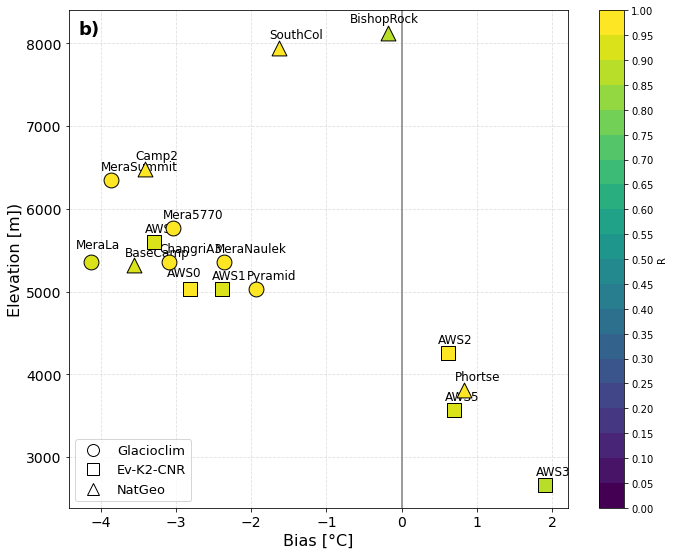

In [55]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm

# One marker per group (cycling)
group_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

# Correlation shading bins (0 → 1)
bins = np.arange(0., 1.05, 0.05)
norm = BoundaryNorm(bins, ncolors=256, clip=True)
cmap = cm.viridis   # better for correlation

legend_handles = []
added_groups = set()

# Loop over groups
for gi, (group, bias_list_lr, corr_list_lr, names_lr, elevs) in enumerate(
        zip(groups, bias_lists_lr, corr_lists_lr, names_lists_lr, elev_stations)
    ):

    marker = group_markers[gi % len(group_markers)]

    for i, name in enumerate(names_lr):

        elev = elevs[name]          # y-axis
        bias = bias_list_lr[i]      # x-axis
        r    = corr_list_lr[i]      # shading

        # Scatter point
        sc = ax.scatter(
            bias, elev,
            s=220,
            marker=marker,
            c=[r], cmap=cmap, norm=norm,
            edgecolor='k', zorder=6
        )
        
        if name in ['MeraLa',]:
            ax.text(
            bias - 0.2,
            elev + 140,
            name,
            fontsize=12,
            ha='left',
            va='bottom'
        )

        elif name in ['AWS0']:
            ax.text(
            bias - 0.3,
            elev + 120,
            name,
            fontsize=12,
            ha='left',
            va='bottom'
        )
        elif name in ['BishopRock']:
            ax.text(
            bias - 0.5,
            elev + 100,
            name,
            fontsize=12,
            ha='left',
            va='bottom'
        )

        else:
        # Station label offset slightly
            ax.text(
            bias - 0.126,
            elev + 80,
            name,
            fontsize=12,
            ha='left',
            va='bottom'
        )

    # Add legend entry (one per group)
    if group not in added_groups:
        added_groups.add(group)
        legend_handles.append(
            Line2D([0], [0],
                   marker=marker, linestyle='None',
                   markersize=12, markerfacecolor="white",
                   markeredgecolor='k',
                   label=group)
        )

# ---- Formatting ----
ax.set_xlabel('Bias [°C]', fontsize=16)
ax.set_ylabel('Elevation [m])', fontsize=16)
#ax.set_title('Temperature: Elevation vs LR-corrected Bias(R)',
#             fontsize=18)#, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.axvline(x=0, linestyle='-', color='grey')
ax.tick_params(axis='both', labelsize=14)

ax.text(
    0.02, 0.98, 'b)',
    transform=ax.transAxes,
    fontsize=18,
    fontweight='bold',
    ha='left',
    va='top'
)

# ---- Legend ----
ax.legend(handles=legend_handles,
          fontsize=13,
          frameon=True,
          loc='lower left')

# ---- Colorbar: correlation ----
cbar = plt.colorbar(sc, ax=ax, boundaries=bins, ticks=bins)
cbar.set_label('R')#, fontsize=14)
#cbar.ax.tick_params(labelsize=12)

plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
})

plt.tight_layout()


#plotname = f'FIG9b_tas_LR_biasX_elevY_colorR_groupMarkers_{domainM}'
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [56]:
fz=18

station_acronyms = {}

for lst in [stations_info_everest,
            stations_info_salerno,
            stations_info_glacioclim]:
    for s in lst:
        station_acronyms[s["Name"]] = s["ID"]
        
station_acronyms.update({
    "MeraLa": "ML",
    "MeraNaulek": "MK",
    "MeraSummit": "MS",
    "Mera5770": "M57",
    "PyramidAWS": "PYG",
    "Pyramid": "PY",
    "BishopRock": "BIS",
    "SouthCol": "SC",
    "Phortse": "PHO",
    "Khare": "KH",
    "Pheriche": "PHE",
    "ChangriNup": "CNG",
    "CHA3": "CHA",
    "Camp2": "C2",
    "BaseCamp": "BC",
    "SouthCol": "SC",
    "BishopRock": "BIS",
    "Phortse": "PHO",
    "ChangriA3": "CHA",
    "MeraLa": "ML",
    "MeraNaulek": "MK",
    "MeraSummit": "MS",
    "Mera5770": "M57",

})

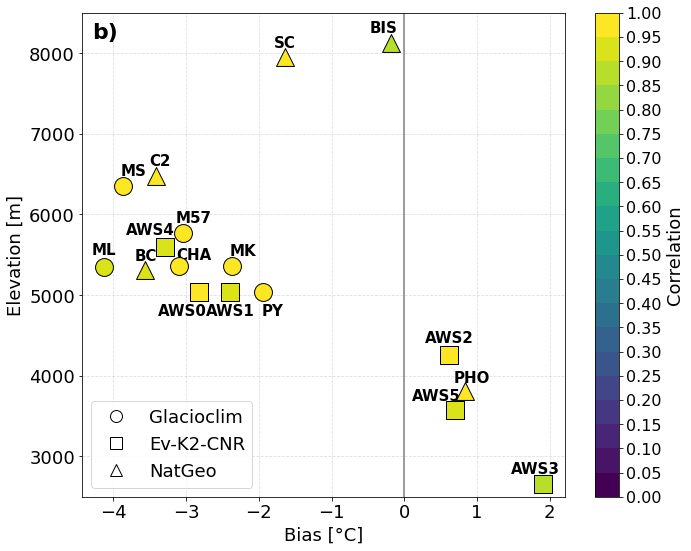

In [57]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm

# ------------------------
# Label offsets
# ------------------------
label_offsets = {
    "ML": (-0.0, 120),
    "BC": (-0.00, 80),
    "CHA": (0.20, 40),
    "AWS4": (-0.2, 120),
    "AWS0": (-0.24, -320),
    "AWS1": (-0.00,-320),
    "PY": (0.12, -320),
    "MK": (0.15, 90),
    "MS": (0.15, 90),
    "M57": (0.15, 90),
    "C2": (0.05, 90),
    "AWS2": (0.00, 120),
    "AWS5": (-0.25, 90),
    "PHO": (0.10, 70),
    "AWS3": (-0.10, 90),
    "SC": (0.00, 90),
    "BIS": (-0.10, 90),
}

group_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

bins = np.arange(0., 1.05, 0.05)
norm = BoundaryNorm(bins, ncolors=256, clip=True)
cmap = cm.viridis

legend_handles = []
added_groups = set()

for gi, (group, bias_list_lr, corr_list_lr, names_lr, elevs) in enumerate(
    zip(groups, bias_lists_lr, corr_lists_lr, names_lists_lr, elev_stations)
):

    marker = group_markers[gi % len(group_markers)]

    for i, name in enumerate(names_lr):

        elev = elevs[name]
        bias = bias_list_lr[i]
        r = corr_list_lr[i]

        sc = ax.scatter(
            bias,
            elev,
            s=320,
            marker=marker,
            c=[r],
            cmap=cmap,
            norm=norm,
            edgecolor='k',
            zorder=6
        )

        label = station_acronyms.get(name, name)
        dx, dy = label_offsets.get(label, (-0.12, 80))

        ax.text(
            bias + dx,
            elev + dy,
            label,
            fontsize=15,
            fontweight='bold',
            ha='center',
            va='bottom'
        )

    if group not in added_groups:
        added_groups.add(group)
        legend_handles.append(
            Line2D(
                [0], [0],
                marker=marker,
                linestyle='None',
                markersize=12,
                markerfacecolor='white',
                markeredgecolor='k',
                label=group
            )
        )
# ---- Formatting ----
ax.set_xlabel('Bias [°C]', fontsize=fz)
ax.set_ylabel('Elevation [m]', fontsize=fz)
#ax.set_title('Temperature: Elevation vs LR-corrected Bias(R)',
#             fontsize=18)#, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.axvline(x=0, linestyle='-', color='grey')
ax.tick_params(axis='both', labelsize=fz)
ax.set_ylim(2500, 8500)
ax.text(
    0.02, 0.98, 'b)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    ha='left',
    va='top'
)

# ---- Legend ----
ax.legend(handles=legend_handles,
          fontsize=fz,
          frameon=True,
          loc='lower left')

# ---- Colorbar: correlation ----
cbar = plt.colorbar(sc, ax=ax, boundaries=bins, ticks=bins)
cbar.set_label('Correlation', fontsize=fz)
#cbar.ax.tick_params(labelsize=12)

plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 18,
})

plt.tight_layout()


#plotname = f'FIG9b_tas_LR_biasX_elevY_colorR_groupMarkers_{domainM}_rev1_lr_khumbu'
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()
